In [23]:
import sys, os
sys.path.append("../app/")

import temframe
import matplotlib.pyplot as plt
import numpy as np
import torch, pandas as pd
import panels


In [24]:
with open("O:/Nat-Tech_HGG-Projects/Projects/2025_GEM_Kenya/Data/202511/Eliye_Spring_1/Data/2025_1114/USF_Files_Eliye_Spring_1/Eliye_Spring_1_usf.zip", "rb") as f:
#with open("C:/Users/au646858/Downloads/USF_Files_dawa river.zip", "rb") as f:
    df = temframe.TEMframe.from_zip(f.read())

forwards = df.forward_operators
dmfwr = df.dmfwr
history = df.history.copy()
sites = df['site_id']
# df = temframe.TEMframe.from_pandas(df[(sites<10)], forward_operators=forwards, history=history)
# df.dmfwr = dmfwr
#df.loc[df['gate_id'].isin([4, 5]), 'error'] = 100.

df.loc[df['error']>100., 'inuse_auto'] = False
#df['error'] = df['error'].clip(10., None)
df.loc[df['sys_gate'].isin([4e-6, 5e-6]), 'inuse_auto'] = False
df.loc[df['sys_gate'].isin([1., 1.000001e-6]), 'inuse_auto'] = False

In [25]:
df.sys_gate.unique()

array([-1.000000e-06,  0.000000e+00,  1.000000e-06,  2.000000e-06,
        3.000000e-06,  4.000000e-06,  5.000000e-06,  9.999990e-01,
        1.000000e+00,  1.000001e+00,  1.000002e+00,  1.000003e+00,
        1.000004e+00,  1.000005e+00,  1.000006e+00,  1.000007e+00,
        1.000008e+00,  1.000009e+00,  1.000010e+00,  1.000011e+00,
        1.000012e+00,  1.000013e+00,  1.000014e+00,  1.000015e+00,
        1.000016e+00,  1.000017e+00,  1.000018e+00,  1.000019e+00,
        1.000020e+00,  1.000021e+00])

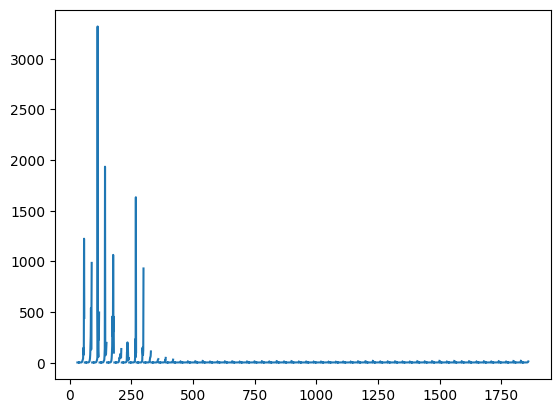

In [26]:
plt.figure()
plt.plot(df.error)

In [27]:
# df = df[df['site_id']<25]
df_overview = df.overview()

In [28]:
df1 = temframe.TEMframe.from_pandas(df[(sites<10)], forward_operators=forwards, history=history)
df1.dmfwr = dmfwr
panels.dbdtSounding(dataframe=df1).render()

In [31]:
from anemone.inversion import LogResistivity
from anemone.inversion import Inversion, fastJac

def invert_site(self, site_id, vc=0.4, res_start=100., max_iterations=50):
    t_max = max([fwr.times.max().item() for fwr in self.forward_operators])
    d_max = (t_max*4e6)**0.5
    n_layers = 30

    if res_start is None:
        thk = 1.+torch.logspace(-0.5, np.log10(d_max-n_layers+1), n_layers).diff()
        z = thk.cumsum()
        res_start=LogResistivity.smooth(torch.ones(n_layers)*40., z)

    elif isinstance(res_start, float):
        thk = 1.+torch.logspace(-0.5, np.log10(d_max-n_layers+1), n_layers).diff()
        z = thk.cumsum(0)
        res_start=LogResistivity.smooth(torch.ones(n_layers)*res_start, z)
    d_obs, d_err, df_site = self.get_site_data(site_id)
    print('d_obs = ', d_obs)
    print('d_err = ', d_err)
    # d_obs = torch.from_numpy(d_obs.numpy()).to(torch.float)
    # d_err = torch.from_numpy(d_err.numpy()).to(torch.float)

    inv1 = fastJac(d_obs, d_err, res_start, self.dmfwr)
    inv1.vertical_smoothness=vc
    res_mod=inv1.invert(iter_cap=max_iterations)
    i,row = df_site.overview().iterrows().__next__()
    d_syn = inv1.data_predicted.exp()
    df_site.loc[:, 'dbdt_syn'] = d_syn.numpy()

    rho,thick = res_mod.mod
    rows = []
    tops = np.concatenate([[0], np.cumsum(thick)[:-1]])
    bottoms = np.cumsum(thick)

    for i, (rho, top, bottom) in enumerate(zip(rho, tops, bottoms)):
        rows.append({
            'site_id': df_site['site_id'].values[0],
            'daytime': row['daytime'],
            'date': row['date'],
            'latitude': row['latitude'],
            'longitude': row['longitude'],
            'elevation': row['elevation'],
            'layer': i,
            'resistivity': rho,
            'top_depth': top,
            'bottom_depth': bottom,
            'center_depth': (top + bottom) / 2
        })
    df_layers = self.__class__(rows, history=self.history, forward_operators=self.forward_operators)
    return df_layers, df_site, inv1

In [34]:
df.dmfwr.save('C:/Users/au646858/OneDrive - Aarhus Universitet/Documents/_repositories/sea-anemone/prototyping/dmfwr_eliye_spring1')

In [32]:
model2,data2,inv2 = invert_site(df, 31, max_iterations=3)
model1,data1,inv1 = invert_site(df, 30)

d_obs =  tensor([-13.2652, -13.9075, -14.4880, -15.0030, -15.4425, -15.8108, -15.2540,
        -15.6625, -16.0183, -16.3622, -16.7070, -17.0591, -17.4193, -17.7953,
        -18.1892, -18.6089, -19.0497, -19.5148, -19.9874, -20.4797, -20.9859,
        -21.4945, -22.0251, -22.5574, -23.1490, -23.7480, -24.3312, -24.9615],
       dtype=torch.float64)
d_err =  tensor([0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296,
        0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296,
        0.0296, 0.0297, 0.0299, 0.0301, 0.0306, 0.0325, 0.0369, 0.0465, 0.0672,
        0.1042], dtype=torch.float64)
tensor([-2.5226, -2.4774, -2.3887, -2.2584, -2.0886, -1.8829, -1.6458, -1.3834,
        -1.1030, -0.8137, -0.5260, -0.2525, -0.0077,  0.1914,  0.3262,  0.3758,
         0.3190,  0.1353, -0.1910, -0.6651, -1.2741, -1.9774, -2.6983, -3.3244,
        -3.7261, -3.8008, -3.5381, -3.0695, -2.6535, -2.5714],
       dtype=torch.float64)
001	misfit:	28.22
tensor([ 2.037

In [ ]:
#model,data = df1.invert_site(30)
model2,data2,inv2 = df.invert_site(31, max_iterations=3)
model1,data1,inv1 = df.invert_site(30)


tensor([-2.5226, -2.4774, -2.3887, -2.2584, -2.0886, -1.8829, -1.6458, -1.3834,
        -1.1030, -0.8137, -0.5260, -0.2525, -0.0077,  0.1914,  0.3262,  0.3758,
         0.3190,  0.1353, -0.1910, -0.6651, -1.2741, -1.9774, -2.6983, -3.3244,
        -3.7261, -3.8008, -3.5381, -3.0695, -2.6535, -2.5714],
       dtype=torch.float64)
001	misfit:	28.22
tensor([ 2.0370e+00,  2.0577e+00,  1.8767e+00,  1.3725e+00,  5.4222e-01,
        -5.2498e-01, -1.7014e+00, -2.8693e+00, -3.9459e+00, -4.8858e+00,
        -5.6712e+00, -6.2990e+00, -6.7707e+00, -7.0860e+00, -7.2391e+00,
        -7.2185e+00, -7.0060e+00, -6.5786e+00, -5.9095e+00, -4.9719e+00,
        -3.7468e+00, -2.2560e+00, -6.8561e-01,  4.0289e-01,  6.4033e-01,
         8.5768e-01,  9.2330e-01,  4.9796e-01, -1.4855e-03, -1.6320e-01],
       dtype=torch.float64)
002	misfit:	72.99
tensor([13.7110, 13.6119, 13.6403, 13.9148, 14.4223, 15.0208, 15.4239, 15.0900,
        13.2738, 10.8539, 10.1866,  9.1915,  7.4705,  5.8050,  4.0350,  2.1086,
      

In [11]:
panels.dbdtSounding(dataframe=data2).render()

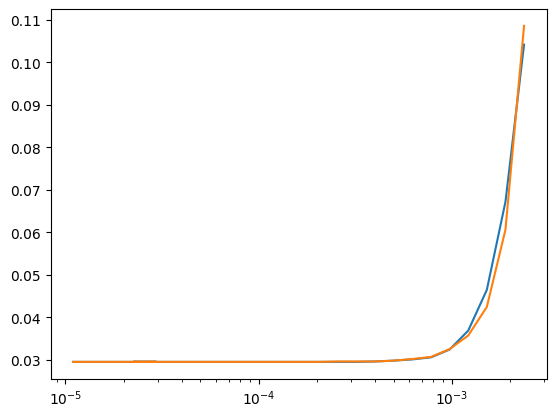

In [78]:
plt.figure()
# plt.semilogx(df1.dmfwr.times, inv2.data_observed)
# plt.semilogx(df1.dmfwr.times, inv1.data_observed)
plt.semilogx(df1.dmfwr.times, inv2.data_error)
plt.semilogx(df1.dmfwr.times, inv1.data_error)

In [57]:
mpan = panels.ModelGraph(dataframe=model2)
mpan.render()